# Sampling comparison and SHAP — low-review classification

Zaghloul et al. (2024) retrain every classifier under `RandomOverSampler`, `SMOTE` and `ADASYN` (their Experiment 4)
and report accuracy, weighted precision / recall / F1 and AUC-ROC. This notebook repeats that study on our protocol,
adds the two strategies the brief names (no adjustment, class weights) and the imbalance-aware metrics the brief asks
for (PR-AUC, balanced accuracy, Brier), then explains the final model with SHAP.

* **Grid**: 4 models (tuned logistic, decision tree, random forest, CatBoost; configurations from
  `outputs/selected_models.json`) × 5 strategies (`none`, `class_weight`, `random_oversampler`, `smote`, `adasyn`) = 20 fits.
  No re-tuning: the question is what the imbalance strategy does to a fixed model.
* Resampling runs **inside** an imbalanced-learn pipeline after the preprocessor, on training rows only.
  CatBoost uses the forest's numeric matrix here (SMOTE / ADASYN cannot interpolate string categories); its native
  categorical result is the ladder row in `model_comparison.csv`.
* Thresholds are chosen on validation (F1) and frozen; the test set is scored once per cell. The strategy marked
  `*` per model is chosen on **validation** PR-AUC; test columns are reported for every cell for completeness and
  are never used to choose anything.
* **SHAP**: TreeExplainer on the final forest (and CatBoost as a cross-check), with one-hot and indicator columns
  folded back onto the original features; the exact linear SHAP of the logistic model as a sanity check.

Set `QUICK = True` for a dry run (small forests / CatBoost); the report numbers come from `QUICK = False`.

In [1]:
from pathlib import Path
import sys, warnings
_c = Path.cwd()
ROOT = next((p for parent in [_c, *_c.parents]
             for p in (parent, parent / "Classification", parent / "Phase 2" / "Classification")
             if (p / "config" / "problem_spec.json").is_file() and (p / "src" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the repository root, Phase 2, or Phase 2/Classification.")
sys.path.insert(0, str(ROOT / "src"))
import paths  # adds Phase 2/Regression/historical_temporal/src (regression package) to sys.path as well
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import clf_config as config, clf_features as features, clf_split as split, clf_pipelines as pipelines, clf_evaluate as evaluate
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ACCENT, GREY, RED = "#2563eb", "#9ca3af", "#dc2626"
for d in (config.FIGURES_DIR, config.RESULTS_DIR, config.PROCESSED_DIR, config.MODELS_DIR): d.mkdir(parents=True, exist_ok=True)
print("package root:", ROOT)
import joblib, json, time
from sklearn.base import clone
import clf_sampling as sampling, clf_explain as explain

QUICK = False
PROBLEM = "p2"
OUT = config.ROOT / "outputs"
best = json.load(open(OUT / "selected_models.json"))
print("configurations from baseline_variant_review | final model:", best["final_model"], "| quick:", best["quick_mode"])

package root: c:\Users\wanglr\Downloads\scp5006\IT5006-clean\Phase 2\Classification
configurations from baseline_variant_review | final model: B_rf | quick: False


## 1. Data

In [2]:
df = features.load_feature_table()
cohort = features.cohort(df, PROBLEM)
S = split.split_frame(cohort)
X_tr, y_tr = split.xy(S["train"], PROBLEM); X_va, y_va = split.xy(S["validation"], PROBLEM); X_te, y_te = split.xy(S["test"], PROBLEM)
print({k: v.shape for k, v in S.items()}, "| positive rate", round(y_tr.mean(), 4))

{'train': (52254, 78), 'validation': (13064, 78), 'test': (32172, 78)} | positive rate 0.1415


## 2. The 20 fits

Tuned parameters are taken from the ladder; the CatBoost iteration count is the early-stopped one when it was retained.
`fit_seconds` and `train_rows_after_sampling` are recorded because the paper's main finding about resampling is cost.

In [3]:
params = {m: dict(best["best_params"].get(m, {})) for m in sampling.MODELS}
if QUICK:
    params["B_rf"]["model__n_estimators"] = 100; params["B_catboost"]["model__iterations"] = 150
rows, fitted, proba = [], {}, {}
for model in sampling.MODELS:
    for strategy in sampling.STRATEGIES:
        t0 = time.time()
        pipe = sampling.build(model, strategy, PROBLEM, params[model]).fit(X_tr, y_tr)
        p_va, p_te = pipe.predict_proba(X_va)[:, 1], pipe.predict_proba(X_te)[:, 1]
        thr = evaluate.best_threshold(y_va, p_va)
        mv, mt = evaluate.classification_metrics(y_va, p_va, thr), evaluate.classification_metrics(y_te, p_te, thr)
        n_after = len(y_tr)
        if strategy not in ("none", "class_weight"):
            n_after = len(pipe.named_steps["sample"].fit_resample(pipe[:2].transform(X_tr), y_tr)[1])   # history -> pre
        rows.append({"model": model, "strategy": strategy, "fit_seconds": round(time.time() - t0, 1),
                     "train_rows_after_sampling": n_after, "threshold": thr,
                     **{f"val_{k}": v for k, v in mv.items() if k != "threshold"},
                     **{f"test_{k}": v for k, v in mt.items() if k != "threshold"}})
        fitted[(model, strategy)], proba[(model, strategy)] = pipe, (p_va, p_te)
        print(f"{model:15s} {strategy:19s} val PR-AUC {mv['pr_auc']:.3f}  test PR-AUC {mt['pr_auc']:.3f}  "
              f"ROC {mt['roc_auc']:.3f}  Brier {mt['brier']:.3f}  rows {n_after:6d}  {time.time()-t0:.0f}s")
res = pd.DataFrame(rows).set_index(["model", "strategy"])
res.to_csv(OUT / "tables/sampling_comparison.csv")

A_linear_tuned  none                val PR-AUC 0.471  test PR-AUC 0.493  ROC 0.784  Brier 0.093  rows  52254  3s
A_linear_tuned  class_weight        val PR-AUC 0.469  test PR-AUC 0.490  ROC 0.786  Brier 0.166  rows  52254  3s
A_linear_tuned  random_oversampler  val PR-AUC 0.468  test PR-AUC 0.490  ROC 0.786  Brier 0.166  rows  89720  5s
A_linear_tuned  smote               val PR-AUC 0.465  test PR-AUC 0.489  ROC 0.783  Brier 0.166  rows  89720  5s
A_linear_tuned  adasyn              val PR-AUC 0.457  test PR-AUC 0.480  ROC 0.782  Brier 0.198  rows  90716  6s
B_tree_base     none                val PR-AUC 0.469  test PR-AUC 0.476  ROC 0.771  Brier 0.094  rows  52254  3s
B_tree_base     class_weight        val PR-AUC 0.469  test PR-AUC 0.484  ROC 0.771  Brier 0.167  rows  52254  3s
B_tree_base     random_oversampler  val PR-AUC 0.452  test PR-AUC 0.476  ROC 0.770  Brier 0.164  rows  89720  5s
B_tree_base     smote               val PR-AUC 0.444  test PR-AUC 0.470  ROC 0.759  Brier 0.103 

## 3. Results

Two views of the same table: (a) the imbalance-aware metrics the brief asks for, (b) the paper's metrics
(accuracy and class-size-weighted precision / recall / F1), which are dominated by the 86% majority class and
therefore barely move between strategies. The best strategy per model by **validation** PR-AUC is marked.

In [4]:
cols_a = ["val_pr_auc", "test_pr_auc", "test_roc_auc", "test_balanced_acc", "test_brier", "test_precision", "test_recall", "test_f1", "test_flag_rate", "threshold", "fit_seconds"]
tab_a = res[cols_a].round(3)
best_by_model = res.groupby(level=0).val_pr_auc.idxmax()
tab_a["best_on_validation"] = ["*" if idx in set(best_by_model) else "" for idx in res.index]
display(tab_a)
cols_b = ["test_accuracy", "test_precision_weighted", "test_recall_weighted", "test_f1_weighted", "test_roc_auc", "train_rows_after_sampling"]
res[cols_b].round(3)

val_pr_auc  test_pr_auc  test_roc_auc  test_balanced_acc  test_brier  test_precision  test_recall  test_f1  test_flag_rate  \
model          strategy                                                                                                                                         
A_linear_tuned none                     0.471        0.493         0.784              0.712       0.093           0.546        0.491    0.517           0.127   
               class_weight             0.469        0.490         0.786              0.713       0.166           0.545        0.494    0.518           0.128   
               random_oversampler       0.468        0.490         0.786              0.714       0.166           0.542        0.497    0.519           0.130   
               smote                    0.465        0.489         0.783              0.718       0.166           0.518        0.516    0.517           0.141   
               adasyn                   0.457        0.480         0.782              0.719       0.198           0.511        0.520    0.515           0.144   
B_tree_base    none                     0.469        0.476         0.771              0.712       0.094           0.547        0.492    0.518           0.127   
               class_weight             0.469        0.484         0.771              0.723       0.167           0.468        0.549    0.505           0.166   
               random_oversampler       0.452        0.476         0.770              0.707       0.164           0.522        0.486    0.504           0.132   
               smote                    0.444        0.470         0.759              0.711       0.103           0.506        0.503    0.505           0.141   
               adasyn                   0.445        0.463         0.758              0.703       0.103           0.535        0.474    0.503           0.126   
B_rf           none                     0.491        0.506         0.788              0.715       0.092           0.537        0.502    0.519           0.132   
               class_weight             0.491        0.505         0.788              0.720       0.145           0.508        0.523    0.515           0.146   
               random_oversampler       0.489        0.505         0.787              0.714       0.146           0.542        0.498    0.519           0.130   
               smote                    0.477        0.498         0.782              0.706       0.099           0.555        0.476    0.512           0.121   
               adasyn                   0.477        0.496         0.781              0.710       0.099           0.545        0.488    0.515           0.127   
B_catboost     none                     0.487        0.509         0.789              0.716       0.092           0.536        0.505    0.520           0.133   
               class_weight             0.485        0.502         0.788              0.708       0.160           0.559        0.479    0.516           0.121   
               random_oversampler       0.484        0.501         0.789              0.714       0.157           0.538        0.499    0.518           0.131   
               smote                    0.480        0.505         0.786              0.716       0.093           0.530        0.506    0.517           0.135   
               adasyn                   0.481        0.505         0.786              0.718       0.093           0.522        0.514    0.518           0.139   

                                   threshold  fit_seconds best_on_validation  
model          strategy                                                       
A_linear_tuned none                    0.248          2.9                  *  
               class_weight            0.684          2.8                     
               random_oversampler      0.675          4.6                     
               smote                   0.622          4.7                     
               ada

test_accuracy  test_precision_weighted  test_recall_weighted  test_f1_weighted  test_roc_auc  train_rows_after_sampling
model          strategy                                                                                                                                   
A_linear_tuned none                        0.870                    0.865                 0.870             0.867         0.784                      52254
               class_weight                0.870                    0.865                 0.870             0.867         0.786                      52254
               random_oversampler          0.869                    0.865                 0.869             0.867         0.786                      89720
               smote                       0.864                    0.863                 0.864             0.863         0.783                      89720
               adasyn                      0.862                    0.863                 0.862             0.862         0.782                      90716
B_tree_base    none                        0.870                    0.865                 0.870             0.868         0.771                      52254
               class_weight                0.848                    0.859                 0.848             0.853         0.771                      52254
               random_oversampler          0.864                    0.860                 0.864             0.862         0.770                      89720
               smote                       0.860                    0.860                 0.860             0.860         0.759                      89720
               adasyn                      0.867                    0.861                 0.867             0.864         0.758                      90015
B_rf           none                        0.868                    0.865                 0.868             0.866         0.788                      52254
               class_weight                0.861                    0.863                 0.861             0.862         0.788                      52254
               random_oversampler          0.869                    0.865                 0.869             0.867         0.787                      89720
               smote                       0.872                    0.865                 0.872             0.868         0.782                      89720
               adasyn                      0.870                    0.864                 0.870             0.867         0.781                      90015
B_catboost     none                        0.868                    0.865                 0.868             0.866         0.789                      52254
               class_weight                0.873                    0.866                 0.873             0.869         0.788                      52254
               random_oversampler          0.869                    0.865                 0.869             0.866         0.789                      89720
               smote                       0.867                    0.864                 0.867             0.865         0.786                      89720
               adasyn                      0.865                    0.864                 0.865             0.864         0.786                      90015

In [5]:
# strategy effect relative to 'none', per model (test PR-AUC and Brier)
delta = res.test_pr_auc.unstack("strategy")[sampling.STRATEGIES]
delta_brier = res.test_brier.unstack("strategy")[sampling.STRATEGIES]
print("test PR-AUC by strategy"); display(delta.round(3))
print("test Brier by strategy (lower is better)"); display(delta_brier.round(3))

test PR-AUC by strategy


strategy,none,class_weight,random_oversampler,smote,adasyn
model,,,,,
A_linear_tuned,0.493,0.490,0.490,0.489,0.480
B_catboost,0.509,0.502,0.501,0.505,0.505
B_rf,0.506,0.505,0.505,0.498,0.496
B_tree_base,0.476,0.484,0.476,0.470,0.463


test Brier by strategy (lower is better)


strategy,none,class_weight,random_oversampler,smote,adasyn
model,,,,,
A_linear_tuned,0.093,0.166,0.166,0.166,0.198
B_catboost,0.092,0.160,0.157,0.093,0.093
B_rf,0.092,0.145,0.146,0.099,0.099
B_tree_base,0.094,0.167,0.164,0.103,0.103


## 4. Figure (report Figure 5)

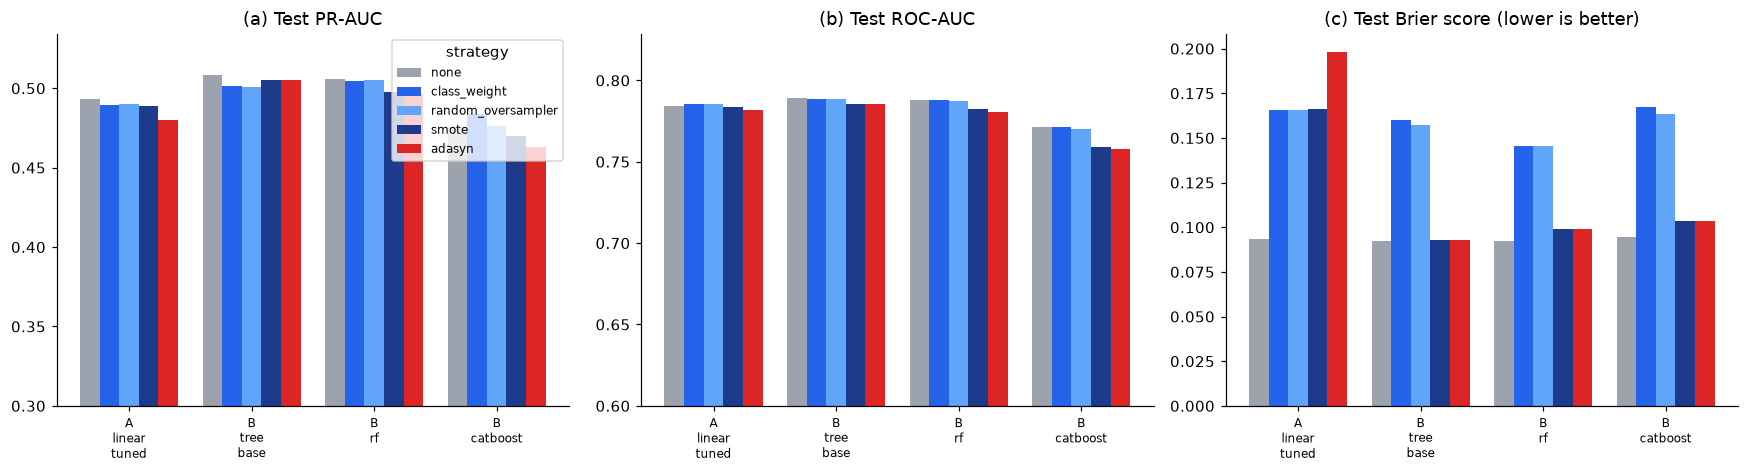

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
pal = dict(zip(sampling.STRATEGIES, [GREY, ACCENT, "#60a5fa", "#1e3a8a", RED]))
w = 0.16; x = np.arange(len(sampling.MODELS))
for j, strat in enumerate(sampling.STRATEGIES):
    ax[0].bar(x + (j - 2) * w, delta[strat].values, w, color=pal[strat], label=strat)
    ax[1].bar(x + (j - 2) * w, res.test_roc_auc.unstack("strategy")[strat].values, w, color=pal[strat])
    ax[2].bar(x + (j - 2) * w, delta_brier[strat].values, w, color=pal[strat])
for a, t in zip(ax, ("(a) Test PR-AUC", "(b) Test ROC-AUC", "(c) Test Brier score (lower is better)")):
    a.set_xticks(x); a.set_xticklabels([m.replace("_", "\n") for m in sampling.MODELS], fontsize=8); a.set_title(t)
ax[0].axhline(y_te.mean(), ls="--", color=GREY, lw=1); ax[0].set_ylim(0.3, None); ax[1].set_ylim(0.6, None)
ax[0].legend(fontsize=8, title="strategy")
plt.tight_layout(); fig.savefig(OUT / "figures/05_sampling_comparison.png", bbox_inches="tight")

## 5. SHAP on the final model

`shap.TreeExplainer` on the forest under its retained strategy (positive-class contributions, 1,500 validation rows).
One-hot and missing-indicator columns are summed back onto their original feature for the bar chart so it is
comparable with the permutation importance in `baseline_variant_review`. The beeswarm keeps the transformer columns
so the direction of each effect is visible.

In [7]:
import shap
FINAL = best["final_model"] if best["final_model"] in sampling.MODELS else "B_rf"
FINAL_STRATEGY = 'class_weight' # best_by_model[FINAL][1]
pipe = fitted[(FINAL, FINAL_STRATEGY)]
print("explaining", FINAL, "under", FINAL_STRATEGY)
t0 = time.time()
sv, M, names, base_value, idx = explain.shap_tree(pipe, X_va, max_rows=600 if QUICK else 1500)
print(f"SHAP values {sv.shape} in {time.time()-t0:.0f}s; base value {base_value:.3f}")
grouped = explain.group_by_feature(sv, names, config.features_for(PROBLEM))
grouped.to_csv(OUT / "tables/shap_importance.csv", index=False)
grouped.head(15)

explaining B_rf under class_weight
SHAP values (1500, 121) in 204s; base value 0.500


,feature,mean_abs_shap,columns
0,n_items,0.043098,1
1,is_delivered,0.028947,1
2,seller_id_enc,0.027249,1
3,actual_delivery_time,0.025970,2
4,delivery_vs_seller_prior,0.024617,2
5,wd_delivery_time_delta,0.024147,2
6,carrier_transit_days,0.023529,2
7,wd_actual_delivery_time,0.022838,2
8,delivery_time_delta,0.021139,2
9,seller_prior_low_review_rate,0.013522,1


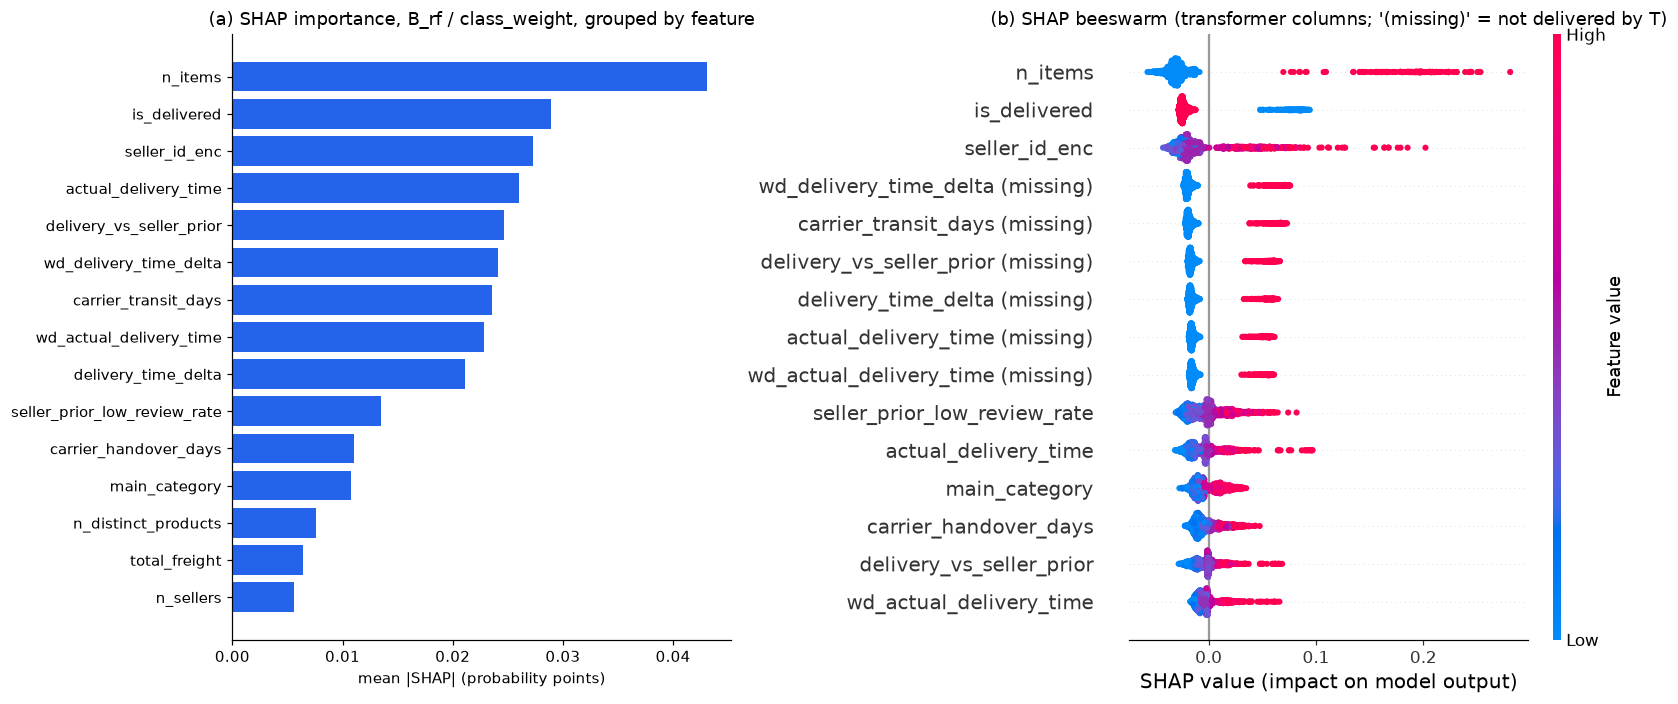

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
top = grouped.head(15)
ax[0].barh(top.feature[::-1], top.mean_abs_shap[::-1], color=ACCENT)
ax[0].set_xlabel("mean |SHAP| (probability points)"); ax[0].set_title(f"(a) SHAP importance, {FINAL} / {FINAL_STRATEGY}, grouped by feature")
plt.sca(ax[1])
short = [explain.original_feature(n, config.features_for(PROBLEM), keep_indicators=True) if n.startswith(("num__", "skew__", "high__")) else n.split("__", 1)[-1] for n in names]
shap.summary_plot(sv, M, feature_names=short, max_display=15, show=False, plot_size=None)
ax[1].set_title("(b) SHAP beeswarm (transformer columns; '(missing)' = not delivered by T)")
plt.tight_layout(); fig.savefig(OUT / "figures/06_shap_summary.png", bbox_inches="tight")

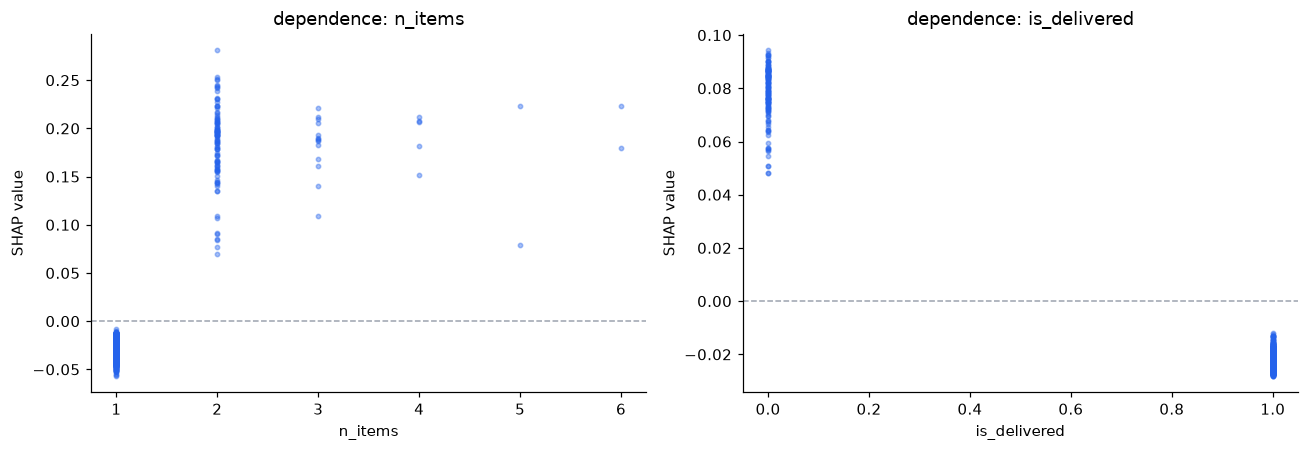

In [9]:
# dependence of the two strongest numeric effects
num_cols = [n for n in names if n.startswith("num__") and "missingindicator" not in n]
top_num = sorted(num_cols, key=lambda n: -np.abs(sv[:, names.index(n)]).mean())[:2]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, n in zip(ax, top_num):
    j = names.index(n); ok = ~np.isnan(M[:, j])
    a.scatter(M[ok, j], sv[ok, j], s=8, alpha=0.4, color=ACCENT)
    a.axhline(0, ls="--", color=GREY, lw=1); a.set_xlabel(n.split("__", 1)[1]); a.set_ylabel("SHAP value")
    a.set_title(f"dependence: {n.split('__', 1)[1]}")
plt.tight_layout(); fig.savefig(OUT / "figures/07_shap_dependence.png", bbox_inches="tight")

### Cross-checks: CatBoost SHAP and exact linear SHAP

If the three model families agree on the top features, the ranking is a property of the data rather than of one
algorithm. Units differ (the forest explains probabilities, CatBoost and the logistic model explain log-odds), so
only the **ranks** are compared: Spearman correlation of the grouped mean |SHAP| is printed.

In [10]:
cb_sv, cb_M, cb_names, _, _ = explain.shap_tree(fitted[("B_catboost", best_by_model["B_catboost"][1])], X_va, max_rows=600 if QUICK else 1500)
cb_grouped = explain.group_by_feature(cb_sv, cb_names, config.features_for(PROBLEM))
lin_sv, lin_M, lin_names, _, _ = explain.shap_linear(fitted[("A_linear_tuned", best_by_model["A_linear_tuned"][1])], X_va, max_rows=600 if QUICK else 1500)
lin_grouped = explain.group_by_feature(lin_sv, lin_names, config.features_for(PROBLEM))
cmp = (grouped.set_index("feature").mean_abs_shap.rename("rf")
       .to_frame().join(cb_grouped.set_index("feature").mean_abs_shap.rename("catboost"))
       .join(lin_grouped.set_index("feature").mean_abs_shap.rename("logistic")))
cmp = cmp.fillna(0).sort_values("rf", ascending=False)
cmp.to_csv(OUT / "tables/shap_cross_model.csv")
print("Spearman rank correlation of grouped mean |SHAP|:"); display(cmp.rank().corr(method="spearman").round(2))
cmp.head(12).round(4)

Spearman rank correlation of grouped mean |SHAP|:


,rf,catboost,logistic
rf,1.00,0.89,0.38
catboost,0.89,1.00,0.49
logistic,0.38,0.49,1.00


,rf,catboost,logistic
feature,,,
n_items,0.0431,0.1615,0.0834
is_delivered,0.0289,0.0853,0.0709
seller_id_enc,0.0272,0.1107,0.0382
actual_delivery_time,0.0260,0.1259,0.0707
delivery_vs_seller_prior,0.0246,0.0834,0.0869
wd_delivery_time_delta,0.0241,0.0540,0.1074
carrier_transit_days,0.0235,0.0520,0.1980
wd_actual_delivery_time,0.0228,0.0828,0.0937
delivery_time_delta,0.0211,0.0483,0.2660


## 6. Save

In [11]:
summary = {"strategies": sampling.STRATEGIES, "models": sampling.MODELS,
           "best_strategy_by_model_on_validation": {m: s for m, s in best_by_model.values},
           "final_model": FINAL, "final_strategy": FINAL_STRATEGY, "quick_mode": QUICK,
           "test_pr_auc": {f"{m}/{s}": round(v, 4) for (m, s), v in res.test_pr_auc.items()},
           "shap_top10": grouped.head(10).feature.tolist()}
json.dump(summary, open(OUT / "sampling_summary.json", "w"), indent=2)
joblib.dump({"pipeline": pipe, "model": FINAL, "strategy": FINAL_STRATEGY, "threshold": float(res.loc[(FINAL, FINAL_STRATEGY), "threshold"])},
            config.MODELS_DIR / "sampling_final.joblib")
print(json.dumps({k: summary[k] for k in ("best_strategy_by_model_on_validation", "final_model", "final_strategy", "shap_top10")}, indent=2))

{
  "best_strategy_by_model_on_validation": {
    "A_linear_tuned": "none",
    "B_catboost": "none",
    "B_rf": "none",
    "B_tree_base": "class_weight"
  },
  "final_model": "B_rf",
  "final_strategy": "class_weight",
  "shap_top10": [
    "n_items",
    "is_delivered",
    "seller_id_enc",
    "actual_delivery_time",
    "delivery_vs_seller_prior",
    "wd_delivery_time_delta",
    "carrier_transit_days",
    "wd_actual_delivery_time",
    "delivery_time_delta",
    "seller_prior_low_review_rate"
  ]
}


## 7. Reading the results

* **Ranking vs scale.** Compare the PR-AUC and ROC-AUC rows across strategies with the Brier rows: on this target the
  strategies move the probability scale (Brier, flag rate at the default cut) far more than the ranking. The paper's
  accuracy / weighted-F1 gains after oversampling are small for the same reason.
* **Cost.** `train_rows_after_sampling` roughly doubles under oversampling, and `fit_seconds` with it; ADASYN adds the
  most synthetic rows in the hardest regions.
* **Which to retain.** The report should keep the ladder's class-weight choice unless a resampler wins on validation
  PR-AUC by the same ≥ 1% relative rule used elsewhere, and should say so in Section 6.3.
* **SHAP vs permutation importance.** Both are on the validation set; if the top-5 lists agree the interpretation
  section can quote either. Grouped SHAP sums a feature's one-hot and missing-indicator columns per row before taking
  the mean absolute value, so high-cardinality categoricals are not penalised for being spread across columns and the
  "not delivered by T" effect is attributed to the delivery-as-of-T features it belongs to rather than appearing once
  per indicator.